# 02 - Modelling: algorithms x class-imbalance strategies
> **All data in this notebook is synthetic.** It was generated by `src/generate_data.py` from assumptions chosen by the author. Findings demonstrate methodology, not real-world evidence.

**Goal.** Rank customers by 30-day churn risk. **Design:** 80/20 stratified hold-out; 3-fold stratified CV on the training set for model selection; hold-out touched once for final reporting. SMOTE runs *inside* the CV pipeline so synthetic minority samples never leak into validation folds.

In [1]:
import sys, json; sys.path.insert(0, "..")
import pandas as pd, numpy as np
from IPython.display import Image, display
from src import config as C
pd.set_option("display.max_columns", 50); pd.set_option("display.precision", 3)
FIG = C.FIGURES

## 1. Cross-validated comparison (3 algorithms x 3 strategies)

,model,strategy,cv_pr_auc,cv_pr_auc_std,cv_roc_auc,cv_recall_top10,fit_seconds
0,logistic,none,0.650,0.002,0.907,0.648,1.001
1,logistic,class_weight,0.641,0.003,0.908,0.645,1.047
2,logistic,smote,0.632,0.002,0.906,0.634,1.749
3,random_forest,none,0.653,0.009,0.907,0.641,16.727
4,random_forest,class_weight,0.644,0.010,0.907,0.635,17.513
5,random_forest,smote,0.627,0.009,0.900,0.625,43.908
6,xgboost,none,0.677,0.004,0.914,0.661,3.774
7,xgboost,class_weight,0.673,0.008,0.912,0.656,3.774
8,xgboost,smote,0.674,0.007,0.913,0.662,8.429


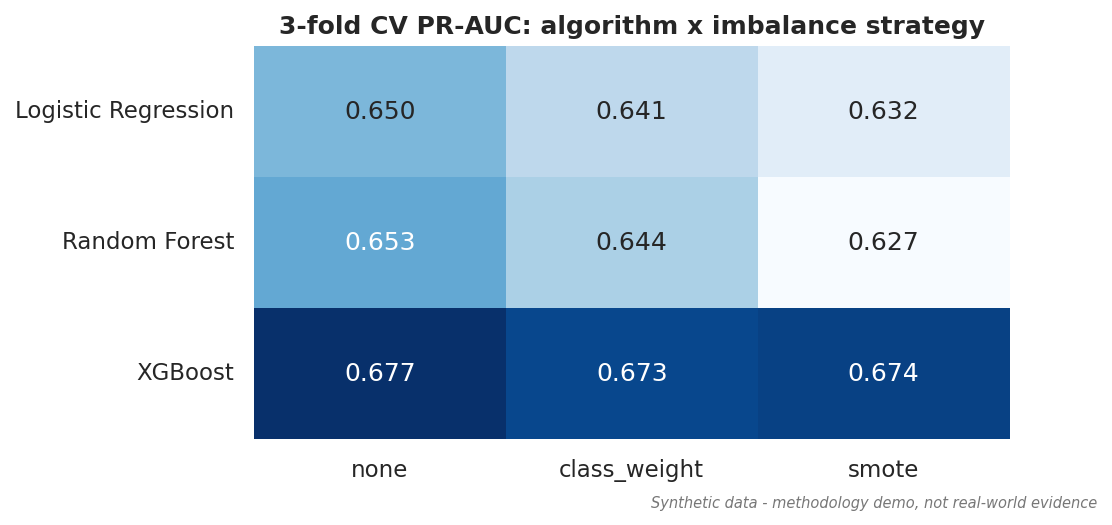

In [2]:
cv = pd.read_csv(C.REPORTS / 'cv_results.csv')
display(cv.round(4))
display(Image(FIG / 'model_cv_comparison.png'))

**What this shows.**
- XGBoost is the best family on every ranking metric (CV PR-AUC 0.677 vs 0.653 for Random Forest and 0.650 for Logistic Regression).
- **Imbalance handling did not help.** 'No resampling' had the highest PR-AUC for all three families; class weights and SMOTE were equal or slightly worse. With ~3,200 positives in training and ranking-based metrics, 8% prevalence is not severe enough to require resampling. SMOTE also interpolates one-hot dummies into fractional values and inflated RF training time ~2.5x.
- The logistic baseline is only ~2.7 PR-AUC points behind XGBoost, which is useful context: a transparent model is a credible fallback.
- Standard deviations across folds (0.002-0.010) are smaller than the XGBoost advantage, so the ordering is stable but the gaps are modest.

## 2. Hold-out results (best strategy per family)

,strategy,roc_auc,pr_auc,recall_at_top10,precision_at_top10,lift_at_top10,recall_at_top5,precision_at_top5
logistic,none,0.906,0.654,0.645,0.511,6.452,0.475,0.752
random_forest,none,0.912,0.671,0.658,0.521,6.578,0.487,0.772
xgboost,none,0.918,0.69,0.669,0.53,6.692,0.506,0.802


Champion: xgboost | hold-out customers: 10000 | base rate: 0.0792


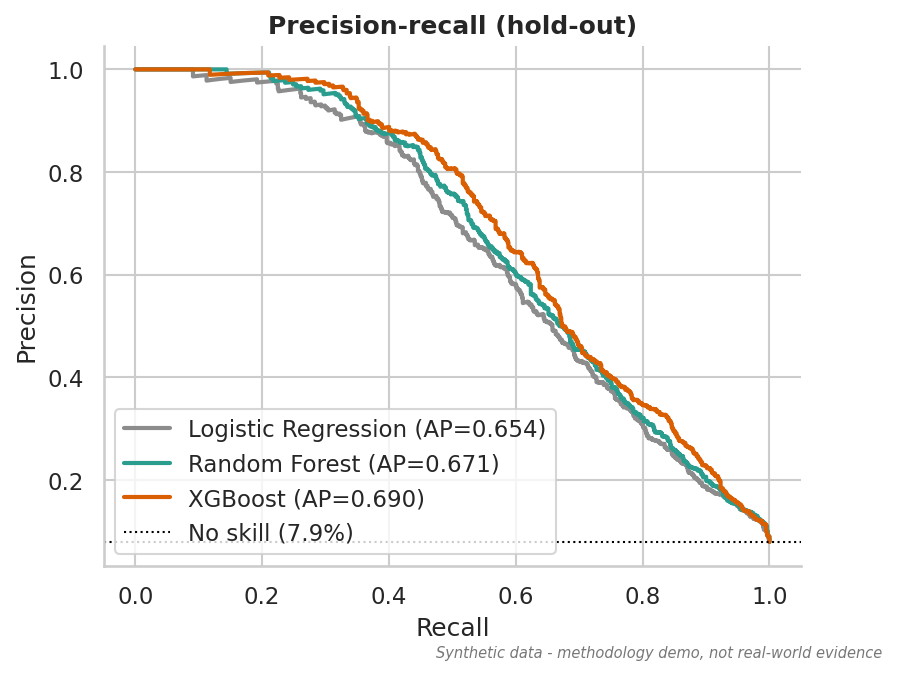

In [3]:
m = json.load(open(C.REPORTS / 'metrics.json'))
h = pd.DataFrame(m['holdout']).T
display(h[['strategy','roc_auc','pr_auc','recall_at_top10','precision_at_top10','lift_at_top10','recall_at_top5','precision_at_top5']].round(3))
print('Champion:', m['champion'], '| hold-out customers:', m['test_rows'], '| base rate:', round(m['test_churn_rate'], 4))
display(Image(FIG / 'model_pr_curves.png'))

**Interpretation.** On the hold-out set XGBoost reaches PR-AUC 0.690 (base rate 0.079, so ~8.7x better than chance), ROC-AUC 0.918, and captures **66.9% of churners in the top 10% of customers** (lift 6.7x). Hold-out numbers track CV closely, so there is no sign of overfitting to the validation folds.

**Caveat.** These scores are on synthetic data with planted signal plus noise. Real-world churn models typically show weaker separation; do not read the absolute values as industry benchmarks.

## 3. What would I do next in a real project?
- Time-based validation (train on earlier snapshots, test on later) to check drift.
- Hyperparameter search (Optuna) and monotonic constraints for tenure/price.
- Calibrated probabilities (done in `train.py` via isotonic regression on out-of-fold predictions) for expected-value decisions.